In [119]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF
import jax.scipy.stats as stats



import scienceplots
import matplotlib.pyplot as plt
import matplotlib_inline

plt.style.use(['science', 'ieee'])
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

Goal is to here do a small experiment, comparing the AGSF algos to optimal nonlinear filter. I would like to use a 1D nonlinear model, for example using a quadratic observation function, to compare to a BPF with very high number of components + KDE (or mixture model). 

In [120]:
# state_dim = 1
# state_noise_dim = 1
# emission_dim = 1
# emission_noise_dim = 1
# seq_length = 100
# mu0 = 0.0 * jnp.zeros(state_dim)
# q0 = jnp.zeros(state_noise_dim)
# r0 = jnp.zeros(emission_noise_dim)
# Sigma0 = 1.0 * jnp.eye(state_dim)
# Q = 0.1 * jnp.eye(state_noise_dim)
# R = 0.1 * jnp.eye(emission_noise_dim)

# # ICASSP
# # f1 = lambda x, q, u: (1-u) * x / 2.  + u * jnp.sin(10 * x) + q
# # f1 = lambda x, q, u:  10 * jnp.sin(10 * x) + q
# # g1 = lambda x, r, u:  0.1 * jnp.dot(x, x) + r
# # def g1lp(x,y,u):
# #     return MVN(loc = g1(x, r0, u), covariance_matrix = R).log_prob(y)

In [121]:
# Parameters
state_dim = 1
state_noise_dim = 1
emission_dim = 1
emission_noise_dim = 1
seq_length = 100
mu0 = 0.0 * jnp.zeros(state_dim)
q0 = jnp.zeros(state_noise_dim)
r0 = jnp.zeros(emission_noise_dim)
Sigma0 = 1.0 * jnp.eye(state_dim)
Q = 0.1 * jnp.eye(state_noise_dim)
R = 0.1 * jnp.eye(emission_noise_dim)

# ICASSP
# f1 = lambda x, q, u: (1-u) * x / 2.  + u * jnp.sin(10 * x) + q
# f1 = lambda x, q, u:  10 * jnp.sin(10 * x) + q
# g1 = lambda x, r, u:  0.1 * jnp.dot(x, x) + r
# def g1lp(x,y,u):
#     return MVN(loc = g1(x, r0, u), covariance_matrix = R).log_prob(y)


# # Lorenz 63
# def lorentz_63(x, sigma=10, rho=28, beta=2.667, dt=0.01):
#     dx = dt * sigma * (x[1] - x[0])
#     dy = dt * (x[0] * rho - x[1] - x[0] *x[2]) 
#     dz = dt * (x[0] * x[1] - beta * x[2])
#     return jnp.array([dx+x[0], dy+x[1], dz+x[2]])
# f63 = lambda x, q, u: lorentz_63(x) + q

# # stochastic growth model
# f3 = lambda x, q, u: x / 2. + 25. * x / (1 + jnp.power(x, 2)) + q
# g3 = lambda x, r, u: u * 0.8 * x + (1-u) * jnp.dot(x, x) + r 
# def g3lp(x,y,u):
#     return MVN(loc = g3(x, 0.0, u), covariance_matrix = R).log_prob(y)


# # Stochastic Volatility
# alpha = 0.91
# sigma = 1.0
# beta = 0.5
# fsv= lambda x, q, u: alpha * x + sigma * q
# gsv = lambda x, r, u: beta * jnp.exp(x/2) * r
# def svlp(x,y,u):
#     return MVN(loc = gsv(x, r0, u), covariance_matrix = gsv(x, 1.0, u)**2 * R).log_prob(y)

# # Linear - Stochastic Volatility
# alpha = 0.91
# sigma = 5.0
# beta = 0.5
# glsv = lambda x, r, u: u * beta * jnp.exp(x/2) * r + (1-u) * (0.8 * x + r)
# def lsvlp(x,y,u):
#     return MVN(loc = glsv(x, r0, u), covariance_matrix = u * beta ** 2 * jnp.exp(x) * R + (1-u) * R).log_prob(y)

# # Multivariate SV
# Phi = 0.8 * jnp.eye(state_dim)
# fmsv = lambda x, q, u: Phi @ x + q #((1-u) + 0.3*u)*q
# gmsv = lambda x, r, u:  u * 0.5 * jnp.multiply(jnp.exp(x/2), r)
# def msvlp(x,y,u):
#     return MVN(loc = gmsv(x, r0, u), covariance_matrix = jnp.diag(jnp.exp(x/2.0)) @ R @ jnp.diag(jnp.exp(x/2.0))).log_prob(y)

# # Linear - Multivariate SV
# sigma = 5.0
# beta = 0.5

# H = 0.1 * jnp.eye(emission_dim, state_dim)
# glmsv = lambda x, r, u: H @ x + r
# # lambda x, r, u: 0 * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-0) * (H @ x + r)
# def lmsvlp(x,y,u):
#     # M = 0 * beta * jnp.diag(jnp.exp(x / sigma)) + (1-0) * jnp.eye(emission_dim)
#     M = jnp.eye(emission_dim)
#     return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)


# Linear-Gaussian SSM
A = 0.8 * jnp.eye(state_dim)
H = 0.1 * jnp.eye(emission_dim, state_dim)
fLG = lambda x, q, u: A @ x + q
gLG = lambda x, r, u: H @ x + r
gLGlp = lambda x,y,u: MVN(loc = gLG(x, 0.0, u), covariance_matrix = R).log_prob(y)

# # Inputs
# # inputs = 8. * jnp.cos(1.2 * jnp.arange(seq_length))
# # sm = lambda x : jnp.exp(x) / (1+jnp.exp(x))
# # inputs = sm(jnp.arange(seq_length)-50) # off - on gradually
# # inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
inputs = jnp.zeros(seq_length) # off.
# inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# # inputs = 1.0 * jnp.ones(seq_length) # on

f = fLG
g = gLG
glp = gLGlp


In [122]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

In [123]:
def pcrlb(key, model, params, seq_length, nsim, inputs):
    # initialize parameters
    f, h = params.dynamics_function, params.emission_function
    F_x, H_x = jacfwd(f, argnums=0), jacfwd(h, argnums=0)
    Qinv = jnp.linalg.inv(params.dynamics_noise_covariance) # DOn't forget to change this for additive model
    Rinv = jnp.linalg.inv(params.emission_noise_covariance)
    # sample nsim state trajectories
    keys = jr.split(key, nsim)
    states, _ = vmap(model.sample, in_axes=(None, 0, None, None))(params, keys, seq_length, inputs)
    # compute arrays of Jacobians
    f_jacobians = vmap(lambda x: vmap(F_x, in_axes=(0, None, 0))(x, params.dynamics_noise_bias, inputs))(states)
    h_jacobians = vmap(lambda x: vmap(H_x, in_axes=(0, None, 0))(x, params.emission_noise_bias, inputs))(states)

    # compute D arrays
    # TODO: remove the G @ Qinv @ G.T for additive model. Only use with additive model
    D11 = vmap(lambda F_array: jnp.sum(vmap(lambda F: F.T @ Qinv @ F)(F_array), axis=0)/nsim, in_axes=(1))(f_jacobians)
    D12 = - jnp.sum(f_jacobians, axis=0) / nsim @ Qinv
    D22 = vmap(lambda H_array: jnp.sum(vmap(lambda H: H.T @ Rinv @ H)(H_array), axis=0)/nsim + Qinv, in_axes=(1))(h_jacobians)

    def _step(carry, t):
        J_prev = carry
        D11_t, D12_t, D22_t = D11[t], D12[t], D22[t]
        J = D22_t - D12_t.T @ jnp.linalg.inv(J_prev + D11_t) @ D12_t
        carry = J
        stack = jnp.linalg.inv(J)
        return carry, stack
    
    J0 = 0 * jnp.eye(state_dim)
    J, CRLB_array = lax.scan(_step, J0, jnp.arange(seq_length))
    return CRLB_array

states, emissions = model.sample(params, jr.PRNGKey(0), seq_length, inputs)
key = jr.PRNGKey(0)
CRLB = pcrlb(key, model, params, seq_length, 1000, inputs)

In [124]:
def mixture_pdf(x, weights, means, covs):
    return jnp.sum(vmap(lambda w, mu, sigma: w * stats.norm.pdf(x, mu, sigma))(weights, means, covs), axis=0)

In [125]:
verbose = False
Nsim = 1
gsf_mse = jnp.zeros(Nsim)
ugsf_mse = jnp.zeros(Nsim)
agsf_mse = jnp.zeros(Nsim)
uagsf_mse = jnp.zeros(Nsim)
bpf_mse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length))
uagsf_norm = jnp.zeros((Nsim, seq_length))
bpf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
next_key = jr.PRNGKey(0)

grid_size = 200
gsf_pdf = jnp.zeros((Nsim, grid_size))
bpf_pdf = jnp.zeros((Nsim, grid_size))
agsf_pdf = jnp.zeros((Nsim, grid_size))
bpf_hist = jnp.zeros((Nsim, grid_size))


states, emissions = model.sample(params, next_key, seq_length, inputs = inputs)
for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    

    # GSF
    M = 1
    tin = time.time()
    posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, key, inputs)
    point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    tout = time.time()
    t_gsf= tout - tin
    print('       Time taken for GSF: ', tout - tin)

    # # U-GSF
    # tin = time.time()
    # uparams = ParamsUKF(1,0,0)
    # posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, key, inputs)
    # point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    # tout = time.time()
    # t_ugsf= tout - tin
    # print('       Time taken for UGSF: ', tout - tin)

    # AGSF
    opt_args = (0.99, 0.99)
    num_components = [100, 5, 5]
    tin = time.time()
    posterior_filtered_agsf, aux_outputs = gf.augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # # U-AGSF
    # tin = time.time()
    # # posterior_filtered_uagsf, aux_outputs = gf.unscented_agsf(params, uparams, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)
    # posterior_filtered_uagsf, aux_outputs = gf.speedy_unscented_agsf(params, uparams, emissions, num_components, key, opt_args, inputs=inputs)
    # point_estimate_uagsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_uagsf.means, posterior_filtered_uagsf.weights), axis=0)
    # tout = time.time()
    # t_uagsf= tout - tin
    # print('       Time taken for UAGSF: ', tout - tin)

    # # BPF
    # tin = time.time()
    # num_particles = 1000000

    # params_bpf = ParamsBPF(
    #     initial_mean=mu0,
    #     initial_covariance=Sigma0,
    #     dynamics_function=f,
    #     dynamics_noise_bias=q0,
    #     dynamics_noise_covariance=Q,
    #     emission_function=g,
    #     emission_noise_bias=r0,
    #     emission_noise_covariance=R,
    #     emission_distribution_log_prob = glp
    # )

    # posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, 1.0)
    # point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    # tout = time.time()
    # t_bpf = tout - tin
    # print('       Time taken for BPF: ', tout - tin)

    gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf - states, axis = 1))
    # ugsf_norm = ugsf_norm.at[i].set(jnp.linalg.norm(point_estimate_ugsf - states, axis = 1))
    agsf_norm = agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_agsf - states, axis = 1))
    # uagsf_norm = uagsf_norm.at[i].set(jnp.linalg.norm(point_estimate_uagsf - states, axis = 1))
    # bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf - states, axis = 1))

    gsf_mse = gsf_mse.at[i].set(jnp.mean(gsf_norm[i]))
    ugsf_mse = ugsf_mse.at[i].set(jnp.mean(ugsf_norm[i]))
    agsf_mse = agsf_mse.at[i].set(jnp.mean(agsf_norm[i]))
    uagsf_mse = uagsf_mse.at[i].set(jnp.mean(uagsf_norm[i]))
    bpf_mse = bpf_mse.at[i].set(jnp.mean(bpf_norm[i]))

    # average PDF plot
    xmin = -5.0
    xmax = +5.0
    x_vals = jnp.linspace(xmin, xmax, grid_size)
    # BPF 
    # kernel = stats.gaussian_kde(posterior_bpf['particles'][:, 99, 0], bw_method = 0.09)    
    # bpf_pdf = bpf_pdf.at[i].set(kernel(x_vals))
    # hist, bin_edges = jnp.histogram(posterior_bpf['particles'][:, 99, 0], bins = grid_size, range = (xmin, xmax), density = True)
    # bpf_hist = bpf_hist.at[i].set(hist)

    # GSF
    weights = posterior_filtered_gsf.weights[:, 99]
    means = posterior_filtered_gsf.means[:, 99]
    vars = posterior_filtered_gsf.covariances[:, 99]

    gsf_pdf = gsf_pdf.at[i].set(mixture_pdf(x_vals, weights, means[:,0], vars[:,0,0]))
    # AGSF

    weights = posterior_filtered_agsf.weights[:, 99]
    means = posterior_filtered_agsf.means[:, 99]
    vars = posterior_filtered_agsf.covariances[:, 99]
   
    agsf_pdf = agsf_pdf.at[i].set(mixture_pdf(x_vals, weights, means[:,0], vars[:,0,0]))



sim 1/1
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for GSF:  0.12378597259521484
       Time taken for AGSF:  1.1042449474334717


In [126]:
print('AGSF MSE: ', jnp.mean(agsf_mse))
print('BPF MSE: ', jnp.mean(bpf_mse))

AGSF MSE:  0.38314265
BPF MSE:  0.0


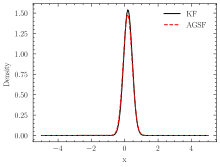

In [131]:
# avg_bpf_pdf = jnp.mean(bpf_pdf, axis=0)
avg_gsf_pdf = jnp.mean(gsf_pdf, axis=0)
avg_agsf_pdf = jnp.mean(agsf_pdf, axis=0)
bw = 0.46

kern = stats.norm.pdf(jnp.arange(-bw,bw, 0.1), 0.0, bw)
kern = kern / jnp.sum(kern)
conv = jnp.convolve(avg_agsf_pdf, kern)
l = len(conv) - grid_size
conv = conv[int(l/2):int(l/2)+grid_size]

plt.plot(x_vals, avg_gsf_pdf, label='KF')
# plt.plot(x_vals, avg_bpf_pdf, label='BPF')
plt.plot(x_vals, avg_agsf_pdf, label='AGSF')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.show()

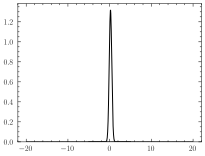

In [128]:
hist = jnp.mean(bpf_hist, axis=0)
plt.bar(bin_edges[:-1], hist, width=jnp.diff(bin_edges), edgecolor="black", align="edge")
plt.plot(x_vals, conv, label='AGSF')
# plt.xlabel('Value')
# plt.ylabel('Density')
# plt.title('Updated Histogram')
plt.show()

In [129]:
# @jit 
# def KL_divergence(mu, Sigma, m, P):
#     return jnp.trace(jnp.linalg.inv(P) @ (Sigma - P + (mu - m) @ (mu - m).T)) + jnp.log(jnp.linalg.det(P) / jnp.linalg.det(Sigma))

# @jit
# def _cov_fn(C, weights, means, covs):
#     mean_c = jnp.einsum('i,ij->j', weights[C], means[C]) / jnp.sum(weights[C])
#     cov_c = (jnp.einsum('i,ijk->jk', weights[C], covs[C]) + jnp.einsum('i,ij->ij', weights[C], means[C]-mean_c).T @ (means[C]-mean_c) ) / jnp.sum(weights[C])
#     return cov_c

# def mixture_reduction(weights, means, covs, red_num, reps=100):
#     prev_num = weights.shape[0]
#     ext_weights = jnp.hstack([weights, jnp.array([0.])])
#     ext_means = jnp.vstack([means, jnp.zeros(means.shape[1])])
#     ext_covs = jnp.vstack((covs, jnp.array([jnp.zeros((covs.shape[1], covs.shape[2]))])))

#     def _step(carry, r):
#         prev_red_means, prev_red_covs = carry
        
#         KLmat = vmap(lambda mu, Sigma: vmap(lambda m, P: KL_divergence(mu, Sigma, m, P))(prev_red_means, prev_red_covs))(means, covs)
#         closest_comp = jnp.argmin(KLmat, axis=1)
#         correspondence_mat = vmap(lambda l: jnp.where (closest_comp == l, jnp.arange(prev_num), -1))(jnp.arange(red_num))
#         red_weights = vmap(lambda C: jnp.sum(ext_weights[C]))(correspondence_mat)
#         red_means = vmap(lambda C: jnp.einsum('i,ij->j', ext_weights[C], ext_means[C]) / jnp.sum(ext_weights[C]))(correspondence_mat)
#         red_covs = vmap(_cov_fn, in_axes=(0, None, None, None))(correspondence_mat, ext_weights, ext_means, ext_covs)

#         red_means = jnp.where(jnp.isnan(red_means), prev_red_means, red_means)
#         red_covs = jnp.where(jnp.isnan(red_covs), prev_red_covs, red_covs)

#         carry = (red_means, red_covs)

#         return carry, (red_weights, red_means, red_covs)

#     red_means = jnp.array([[-10.0],[10.0]])#jr.choice(jr.PRNGKey(0), means, shape=(red_num,))
#     red_covs = jnp.array([[[1.0]],[[1.0]]])#jr.choice(jr.PRNGKey(0), covs, shape=(red_num,))
#     carry = (red_means, red_covs)
#     out = lax.scan(_step, carry, jnp.arange(reps))
#     # out = _step(carry, jnp.arange(reps))

#     return out[1]

In [130]:
# red_weights, red_means, red_covs = mixture_reduction(weights, means, vars, 2)
# red_weights = red_weights[-1]
# red_means = red_means[-1]
# red_covs = red_covs[-1]
# red_covs